In [1]:
# ============================================================
# Clean Neural Data Analysis Pipeline
# ============================================================

import os, math, json, copy
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, Tuple, List

from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error

import umap
import torch
from scipy.signal import butter, filtfilt, hilbert, sawtooth
from scipy.ndimage import gaussian_filter1d
from scipy.stats import circmean, ttest_rel
import pandas as pd

from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import CEBRASKipEncoder, SkippedConvEncoderConfig
from comets.configs import ModalityConfig, SamplingConfig, TrainingConfig
from comets.heads import LinearHead, TwoLayerMLP

import cebra


In [2]:

# ============================================================
# 1. LOAD DATA
# ============================================================
import pickle

session = "ec013.156"
load_path = f"{session}_lfp_spike.pkl"

with open(load_path, "rb") as f:
    data = pickle.load(f)

lfp_raw = data["lfp_raw"]
lfp_theta_full = data["lfp_theta"]  # renamed to avoid conflict
spike_raw = data["spike_raw"]
spike_bin_original = data["spike_bin"]  # renamed to avoid conflict
spike_bin_smoothed = data["spike_bin_smoothed"]
fs_lfp = data["fs_lfp"]
fs_common = data["fs_common"]
theta_band = data["theta_band"]
bin_size_ms = data["bin_size_ms_spike"]
position = data["position"]

print("Dataset loaded successfully")
print(f"LFP raw: {lfp_raw.shape}  (fs={fs_lfp} Hz)")
print(f"LFP theta (50Hz): {lfp_theta_full.shape}")
print(f"Position: {position.shape}")
print(f"Spike bin (20 ms): {spike_bin_original.shape}")

# ============================================================
# 2. PREPROCESSING
# ============================================================

# Normalize spike counts
spike_bin_normalized = (spike_bin_original - spike_bin_original.min(axis=0, keepdims=True)) / \
                       (spike_bin_original.max(axis=0, keepdims=True) - 
                        spike_bin_original.min(axis=0, keepdims=True) + 1e-9)

# Remove channel 65 (not a real channel)
lfp_theta_cleaned = lfp_theta_full[:, 0:-1]

Dataset loaded successfully
LFP raw: (1279488, 65)  (fs=1250 Hz)
LFP theta (50Hz): (51179, 65)
Position: (51179,)
Spike bin (20 ms): (51179, 83)


In [3]:

# ============================================================
# 3. REGION OF INTEREST SELECTION
# ============================================================
window_start = 5000
window_end = 45000

spike_roi = spike_bin_normalized[window_start:window_end, :]
lfp_roi = lfp_theta_cleaned[window_start:window_end, :]
position_roi = position[window_start:window_end]

fat_cebra = np.concatenate([spike_roi,lfp_roi],axis = 1)


print(f"\nROI selected: [{window_start}, {window_end}]")
print(f"Spike ROI: {spike_roi.shape}, LFP ROI: {lfp_roi.shape}")
print(f"fat cebra: {fat_cebra.shape}")



ROI selected: [5000, 45000]
Spike ROI: (40000, 83), LFP ROI: (40000, 64)
fat cebra: (40000, 147)


In [4]:

# ============================================================
# 4. UTILITY FUNCTIONS (defined once)
# ============================================================

def reduce_to_3d(Z):
    """Return a 3-D PCA projection regardless of input dim."""
    Z = np.asarray(Z)
    if Z.shape[1] > 3:
        Z = PCA(n_components=3).fit_transform(Z)
    elif Z.shape[1] < 3:
        pad = np.zeros((Z.shape[0], 3 - Z.shape[1]))
        Z = np.concatenate([Z, pad], axis=1)
    return Z[:, 0], Z[:, 1], Z[:, 2]


def compute_rmse(y_true, y_pred):
    """Compute root mean squared error."""
    return np.sqrt(np.mean((y_true - y_pred) ** 2))


def ridge_decode_with_split(Z, y, train_frac=0.7, alpha=1.0):
    """Train/test ridge decoding with contiguous split."""
    Z = np.asarray(Z)
    y = np.asarray(y).ravel()
    N = len(y)
    ntr = int(train_frac * N)
    
    model = Ridge(alpha=alpha)
    model.fit(Z[:ntr], y[:ntr])
    yhat = model.predict(Z[ntr:])  # test only
    
    return yhat, ntr, model


def compute_decoding_score(Z, y):
    """Decode continuous variable y from embedding Z using ridge regression."""
    Z = np.asarray(Z)
    y = np.asarray(y).ravel()
    n = len(y)
    ntr = int(0.7 * n)
    
    Xtr, Xte = Z[:ntr], Z[ntr:]
    ytr, yte = y[:ntr], y[ntr:]
    
    model = Ridge(alpha=1)
    model.fit(Xtr, ytr)
    yhat = model.predict(Xte)
    
    return r2_score(yte, yhat)



In [5]:

# ============================================================
# 5. TRAIN COMETS MODEL
# ============================================================

# Aliases for convenience
A = spike_roi
B = lfp_roi
C = fat_cebra
color_code = np.linspace(0, 1, window_end - window_start)

# Modality configs
modA = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=A.shape[1], emb_dim=32),
    win_len=8
)
modB = ModalityConfig(
    encoder_cls=CEBRASKipEncoder,
    encoder_cfg=SkippedConvEncoderConfig(in_channels=B.shape[1], emb_dim=16),
    win_len=8
)

sampling = SamplingConfig(
    batch_size=256,
    pos_offset=5,
    negative_mask_dist=16
)

train_cfg = TrainingConfig(
    epochs=100,
    lr=1e-3,
    temperature=1,
    proj_dim=8,
    alpha_cross=0.05,
    beta=0.9,
    head_cls=LinearHead
)

print("\nTraining CoMETs model...")
model = comets.train(A, modA, B, modB, sampling, train_cfg)

ZA_comets = model.embedA(A)
ZB_comets = model.embedB(B)
print(f"CoMETs embeddings - ZA: {ZA_comets.shape}, ZB: {ZB_comets.shape}")



Training CoMETs model...


Training: 100%|██████████| 100/100 [09:31<00:00,  5.72s/it, total=4.7069, within=4.6948, cross=4.9367, lr=0.00e+00]


CoMETs embeddings - ZA: (40000, 8), ZB: (40000, 8)


In [6]:

# ============================================================
# 6. BASELINE EMBEDDINGS
# ============================================================

# PCA
print("\nComputing PCA embeddings...")
ZA_pca = PCA(n_components=3).fit_transform(A)
ZB_pca = PCA(n_components=3).fit_transform(B)

# UMAP
print("Computing UMAP embeddings...")
reducer = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=0)
ZA_umap = reducer.fit_transform(A)
ZB_umap = reducer.fit_transform(B)

# CEBRA - time
print("Computing CEBRA-time embeddings...")
cebra_temp = 1
cebra_itr = 100

modelA_cebra_time = cebra.CEBRA(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    output_dimension=32,
    batch_size=256,
    temperature=cebra_temp,
    verbose=True
)
ZA_cebra_time = modelA_cebra_time.fit_transform(A)

modelB_cebra_time = cebra.CEBRA(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    output_dimension=16,
    batch_size=256,
    temperature=cebra_temp,
    verbose=True
)
ZB_cebra_time = modelB_cebra_time.fit_transform(B)

# CEBRA - behavior
print("Computing CEBRA-behavior embeddings...")
behavior = (position_roi - np.min(position_roi)) / (np.max(position_roi) - np.min(position_roi) + 1e-9)

modelA_cebra_beh = cebra.CEBRA(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    batch_size=256,
    temperature=cebra_temp,
    output_dimension=32,
    verbose=True
)
ZA_cebra_behavior = modelA_cebra_beh.fit_transform(A, behavior)

modelB_cebra_beh = cebra.CEBRA(
    model_architecture='offset10-model',
    max_iterations=cebra_itr,
    batch_size=256,
    temperature=cebra_temp,
    output_dimension=16,
    verbose=True
)
ZB_cebra_behavior = modelB_cebra_beh.fit_transform(B, behavior)



Computing PCA embeddings...
Computing UMAP embeddings...


f:\anaconda\envs\NRMNFD\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Computing CEBRA-time embeddings...


pos: -0.8782 neg:  5.6928 total:  4.8146 temperature:  1.0000: 100%|██████████| 100/100 [00:02<00:00, 41.61it/s]
pos: -0.7375 neg:  5.6723 total:  4.9348 temperature:  1.0000: 100%|██████████| 100/100 [00:01<00:00, 55.49it/s]


Computing CEBRA-behavior embeddings...


pos: -0.5397 neg:  5.7280 total:  5.1883 temperature:  1.0000: 100%|██████████| 100/100 [00:01<00:00, 50.74it/s]
pos: -0.6936 neg:  6.2291 total:  5.5354 temperature:  1.0000: 100%|██████████| 100/100 [00:02<00:00, 43.69it/s]


In [7]:

# ============================================================
# 7. ORGANIZE EMBEDDINGS (consistent naming)
# ============================================================

EMBEDDINGS_A = {
    "CoMETs": ZA_comets,
    "PCA": ZA_pca,
    "UMAP": ZA_umap,
    "CEBRA_time": ZA_cebra_time,
    "CEBRA_behavior": ZA_cebra_behavior
}

EMBEDDINGS_B = {
    "CoMETs": ZB_comets,
    "PCA": ZB_pca,
    "UMAP": ZB_umap,
    "CEBRA_time": ZB_cebra_time,
    "CEBRA_behavior": ZB_cebra_behavior
}

DISPLAY_NAMES = {
    "CoMETs": "CoMETs",
    "PCA": "PCA",
    "UMAP": "UMAP",
    "CEBRA_time": "CEBRA-time",
    "CEBRA_behavior": "CEBRA-behavior"
}


In [8]:

# ============================================================
# 8. COMPUTE DECODING SCORES
# ============================================================

print("\nComputing decoding scores...")
decoding_scores = {}

for method in EMBEDDINGS_A.keys():
    decoding_scores[f'{method}_A'] = compute_decoding_score(EMBEDDINGS_A[method], position_roi)
    decoding_scores[f'{method}_B'] = compute_decoding_score(EMBEDDINGS_B[method], position_roi)

print("\nDecoding scores (R² of position):")
for k, v in decoding_scores.items():
    print(f"{k:20s}: {v:.3f}")

# ============================================================
# 9. COMPUTE TRAJECTORY PREDICTIONS FOR VISUALIZATION
# ============================================================

TRAJECTORY_PREDICTIONS = {}

for method in EMBEDDINGS_A.keys():
    yhat_A, ntr_A, _ = ridge_decode_with_split(EMBEDDINGS_A[method], position_roi)
    yhat_B, ntr_B, _ = ridge_decode_with_split(EMBEDDINGS_B[method], position_roi)
    
    TRAJECTORY_PREDICTIONS[(method, "A")] = {"y_pred": yhat_A, "ntr": ntr_A}
    TRAJECTORY_PREDICTIONS[(method, "B")] = {"y_pred": yhat_B, "ntr": ntr_B}

print("\nTrajectory predictions computed for all methods.")
print("\nSetup complete! Ready for visualization.")


Computing decoding scores...

Decoding scores (R² of position):
CoMETs_A            : 0.693
CoMETs_B            : 0.440
PCA_A               : 0.043
PCA_B               : -0.000
UMAP_A              : 0.044
UMAP_B              : -0.000
CEBRA_time_A        : 0.313
CEBRA_time_B        : -0.005
CEBRA_behavior_A    : 0.473
CEBRA_behavior_B    : -0.004

Trajectory predictions computed for all methods.

Setup complete! Ready for visualization.



Generating population firing rate visualization...


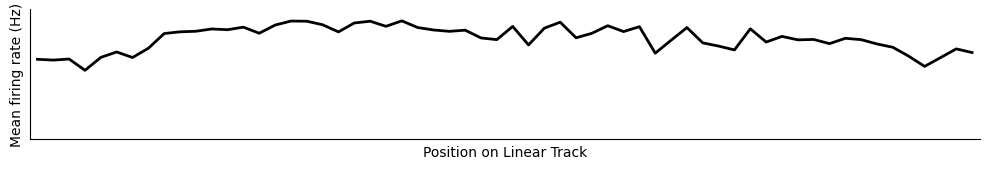

In [9]:


# ============================================================
# VIZ 1: Population Mean Firing Rate vs Position
# ============================================================
print("\nGenerating population firing rate visualization...")

n_bins = 60
edges = np.linspace(np.min(position), np.max(position), n_bins + 1)
cent = 0.5 * (edges[:-1] + edges[1:])

# Compute occupancy
pos_bins = np.clip(np.digitize(position, edges) - 1, 0, n_bins - 1)
occ_counts = np.bincount(pos_bins, minlength=n_bins)
occ_time = occ_counts / fs_common + 1e-9

# Compute coverage (neurons × position)
n_cells = spike_bin_normalized.shape[1]
coverage = np.zeros((n_cells, n_bins))
for i in range(n_cells):
    spk_idx = np.where(spike_bin_normalized[:, i] > 0)[0]
    spk_pos_bins = pos_bins[spk_idx]
    counts = np.bincount(spk_pos_bins, minlength=n_bins)
    coverage[i] = counts / occ_time

mean_rate = coverage.mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 1.8))
ax.plot(cent, mean_rate, color='black', lw=2)
ax.set_xlim(np.min(position), np.max(position))
ax.set_ylim(0, mean_rate.max() * 1.1)
ax.set_xticks([])
ax.set_xticklabels([])
ax.set_ylabel("Mean firing rate (Hz)")
ax.set_xlabel("Position on Linear Track")
ax.set_yticks([])
ax.set_yticklabels([])
ax.grid(False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()



Generating LFP theta-band visualization...


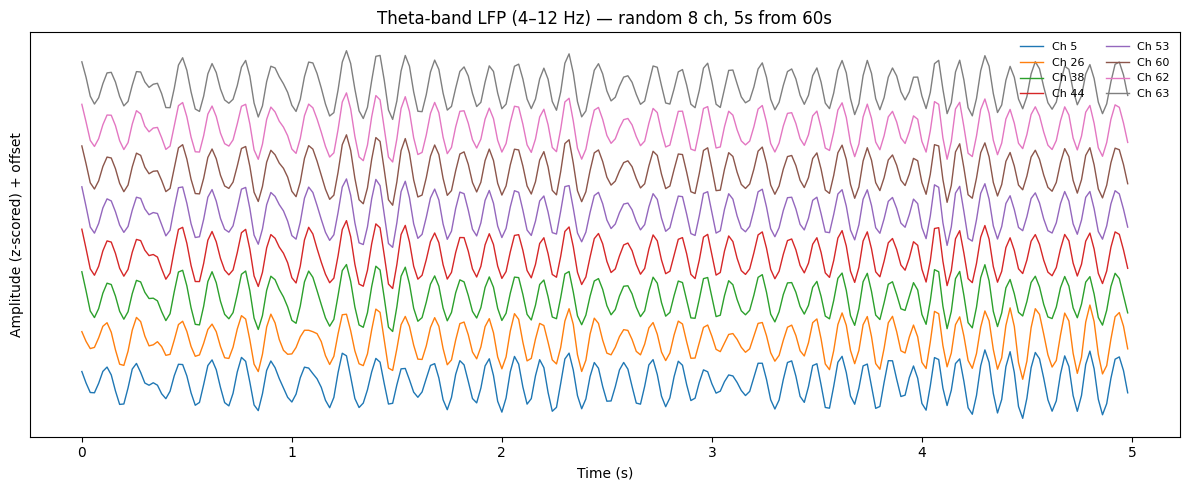

In [10]:

# ============================================================
# VIZ 2: LFP Theta-band Traces (Full Session)
# ============================================================
print("\nGenerating LFP theta-band visualization...")

n_show = 8
sec = 5
start_t = 60
fs = fs_common
offset = 2.5

rng = np.random.default_rng(42)
rand_ch = np.sort(rng.choice(lfp_theta_cleaned.shape[1], size=n_show, replace=False))

start_idx = int(start_t * fs)
end_idx = int((start_t + sec) * fs)
lfp_seg = lfp_theta_cleaned[start_idx:end_idx, rand_ch]

lfp_seg_z = (lfp_seg - np.mean(lfp_seg, axis=0, keepdims=True)) / \
            (np.std(lfp_seg, axis=0, keepdims=True) + 1e-9)

t = np.arange(lfp_seg.shape[0]) / fs

plt.figure(figsize=(12, 5))
for i, ch in enumerate(rand_ch):
    plt.plot(t, lfp_seg_z[:, i] + i * offset, lw=1.0, label=f"Ch {ch}")
plt.title(f"Theta-band LFP (4–12 Hz) — random {n_show} ch, {sec}s from {start_t}s")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (z-scored) + offset")
plt.yticks([])
plt.legend(loc="upper right", ncol=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()



Generating spike raster plot...


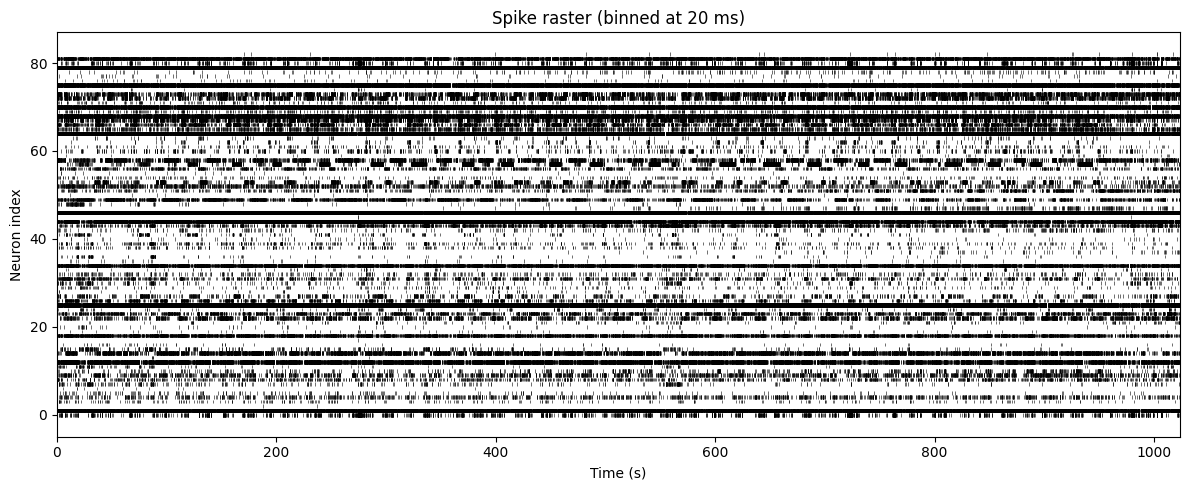

In [11]:

# ============================================================
# VIZ 3: Spike Raster Plot (Full Session)
# ============================================================
print("\nGenerating spike raster plot...")

T, n_cells = spike_bin_normalized.shape
fig, ax = plt.subplots(figsize=(12, 5))

spike_times = [np.where(spike_bin_normalized[:, i] > 0)[0] / fs_common for i in range(n_cells)]

ax.eventplot(spike_times, colors='k',
             lineoffsets=np.arange(n_cells), linelengths=0.8, lw=0.4)
ax.set_xlim(0, T / fs_common)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Neuron index")
ax.set_title("Spike raster (binned at 20 ms)")
plt.tight_layout()
plt.show()



Generating spatial coverage heatmap...


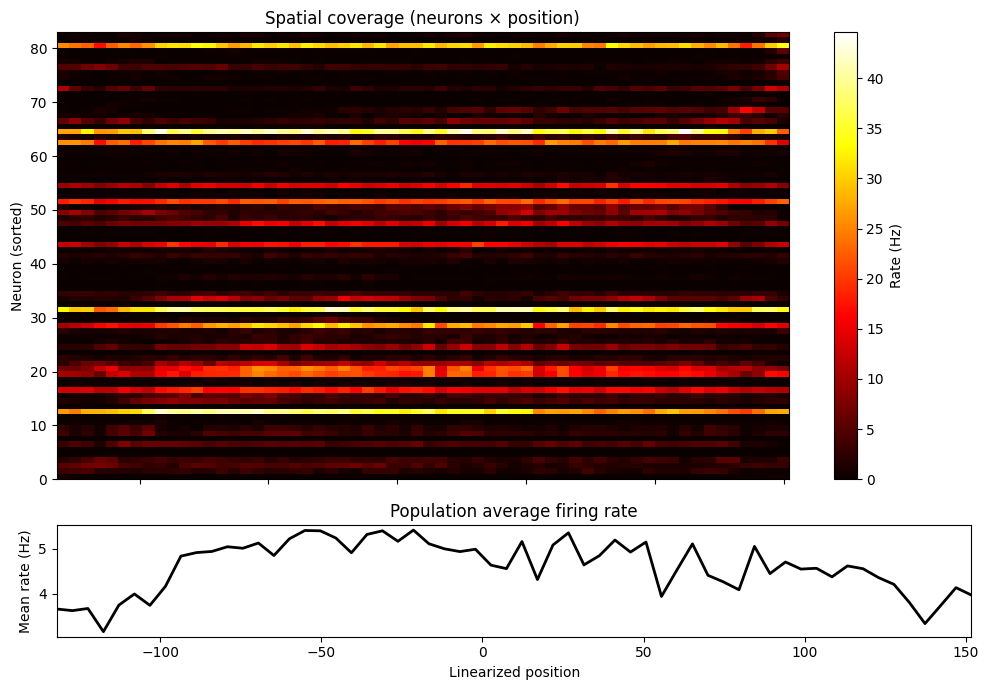

In [12]:

# ============================================================
# VIZ 4: Spatial Coverage Heatmap
# ============================================================
print("\nGenerating spatial coverage heatmap...")

peak_pos = cent[np.argmax(coverage, axis=1)]
order = np.argsort(peak_pos)

fig, ax = plt.subplots(2, 1, figsize=(10, 7),
                       sharex=True, gridspec_kw={'height_ratios': [4, 1]})
im = ax[0].imshow(coverage[order], aspect='auto', origin='lower',
                  extent=[cent[0], cent[-1], 0, n_cells],
                  interpolation='nearest', cmap='hot')
ax[0].set_title("Spatial coverage (neurons × position)")
ax[0].set_ylabel("Neuron (sorted)")
plt.colorbar(im, ax=ax[0], label="Rate (Hz)")

ax[1].plot(cent, mean_rate, color='black', lw=2)
ax[1].set_xlabel("Linearized position")
ax[1].set_ylabel("Mean rate (Hz)")
ax[1].set_title("Population average firing rate")
plt.tight_layout()
plt.show()



Generating ROI LFP + spike raster...


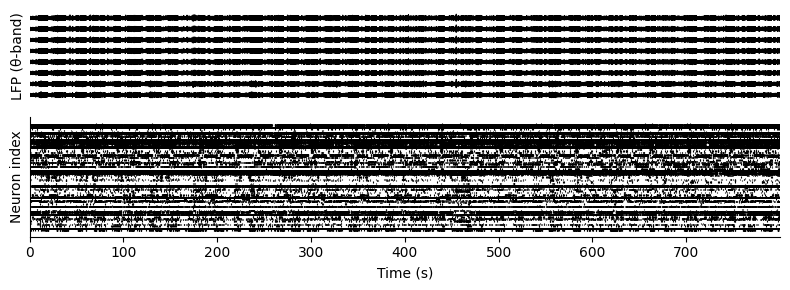

In [13]:

# ============================================================
# VIZ 5: LFP + Spike Raster (ROI)
# ============================================================
print("\nGenerating ROI LFP + spike raster...")

fs = fs_common
offset = 10
n_show = 8

T_roi = lfp_roi.shape[0]
time_roi = np.arange(T_roi) / fs

rng = np.random.default_rng(42)
rand_ch = np.sort(rng.choice(lfp_roi.shape[1], size=n_show, replace=False))

lfp_roi_z = (lfp_roi[:, rand_ch] - np.mean(lfp_roi[:, rand_ch], axis=0, keepdims=True)) / \
            (np.std(lfp_roi[:, rand_ch], axis=0, keepdims=True) + 1e-9)

T_spk, n_cells = spike_roi.shape
spike_times_roi = [np.where(spike_roi[:, i] > 0)[0] / fs for i in range(n_cells)]

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8, 3),
    sharex=True, gridspec_kw={'height_ratios': [1, 1.3]}
)

for i in range(n_show):
    ax1.plot(time_roi, lfp_roi_z[:, i] + i * offset, color='black', lw=0.8)
ax1.set_xlim(time_roi[0], time_roi[-1])
ax1.set_ylabel("LFP (θ-band)")
ax1.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
ax1.spines["bottom"].set_visible(False)
ax1.tick_params(axis="y", left=False, labelleft=False)
for spine in ["top", "right", "left"]:
    ax1.spines[spine].set_visible(False)

ax2.eventplot(spike_times_roi, colors='k',
              lineoffsets=np.arange(n_cells),
              linelengths=1, lw=0.8)
ax2.set_xlim(time_roi[0], time_roi[-1])
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Neuron index")
ax2.tick_params(axis="y", left=False, labelleft=False)
for spine in ["top", "right"]:
    ax2.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()



Generating CoMETs embeddings visualization...


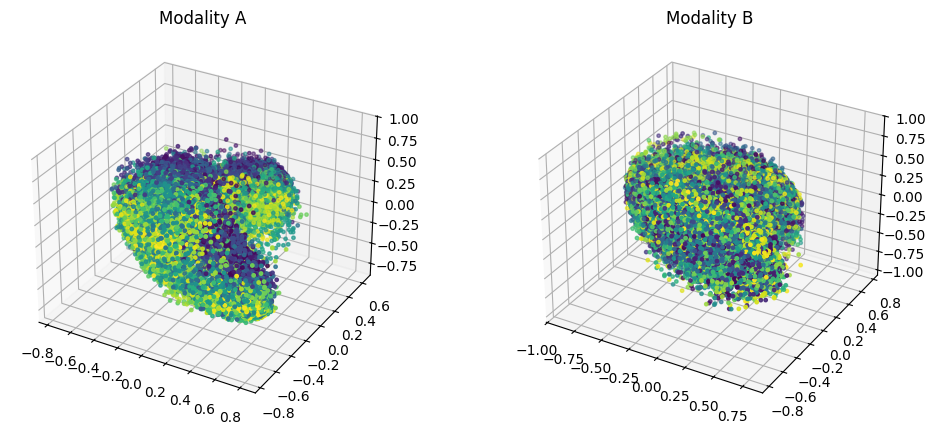

In [14]:

# ============================================================
# VIZ 6: CoMETs Embeddings Visualization
# ============================================================
print("\nGenerating CoMETs embeddings visualization...")

comets.plotemb2(
    ZA_comets, ZB_comets,
    color=color_code,
    titles=("Modality A", "Modality B"),
    mode="direct"
)



Generating embedding comparison (3D)...


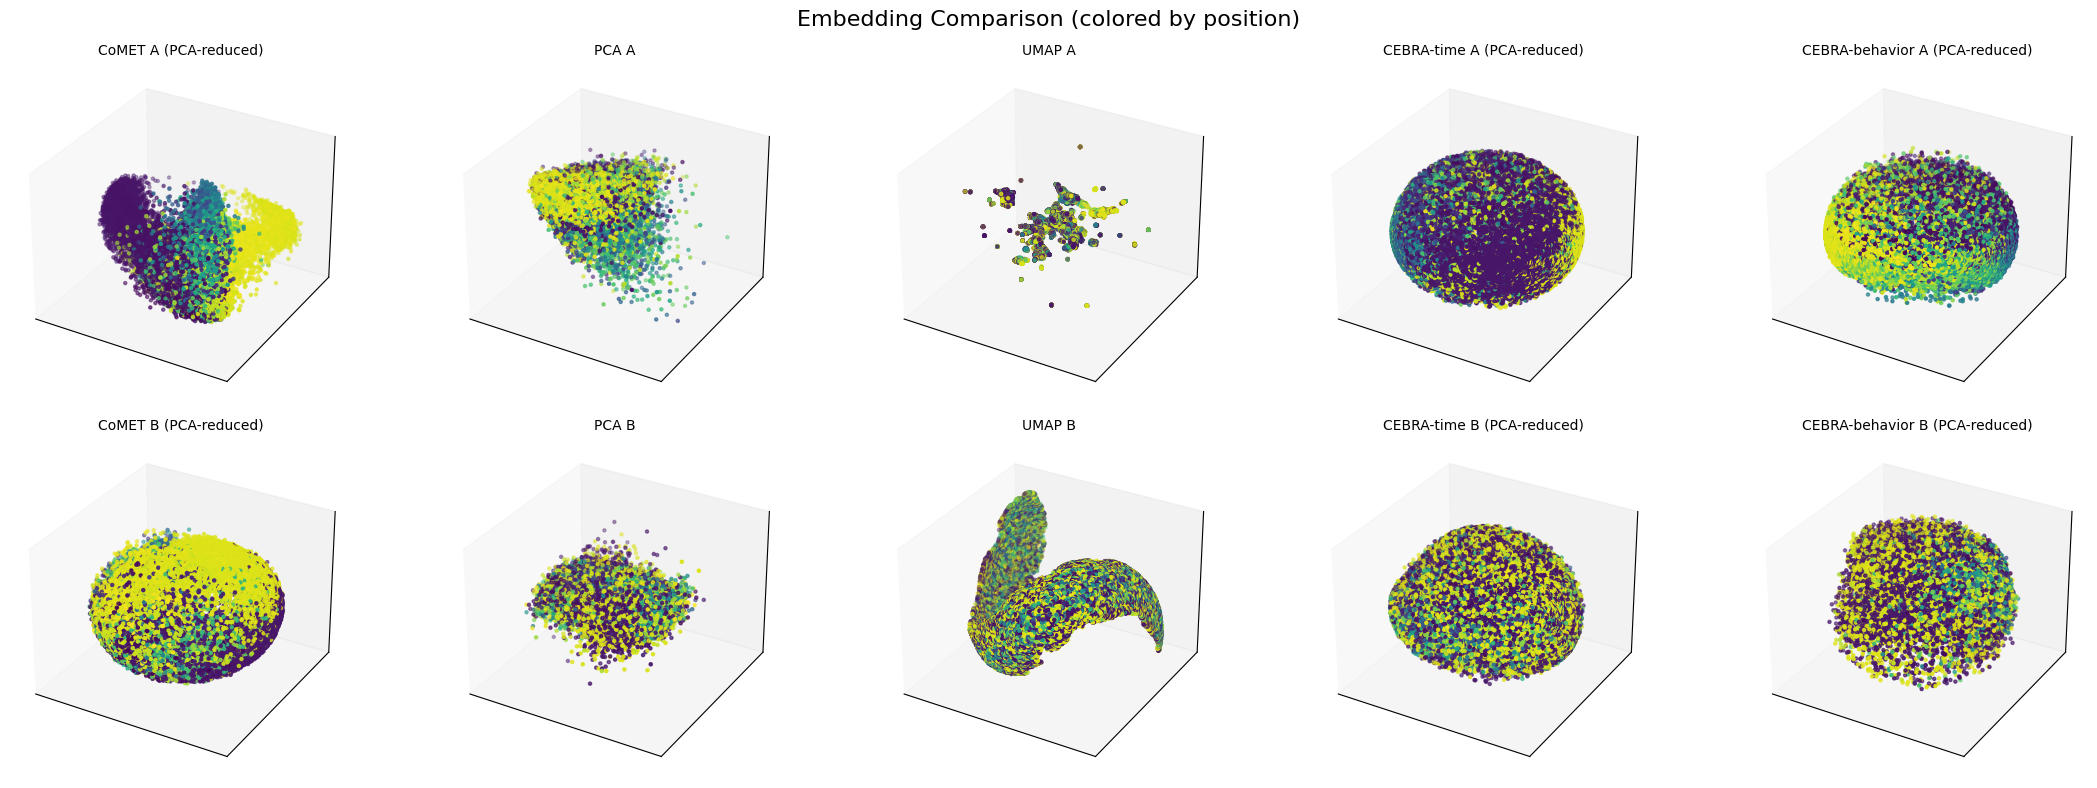

In [15]:

# ============================================================
# VIZ 7: Embedding Comparison (3D, 2x5 grid)
# ============================================================
print("\nGenerating embedding comparison (3D)...")

fig = plt.figure(figsize=(22, 8))

titles_top = [
    "CoMET A (PCA-reduced)",
    "PCA A",
    "UMAP A",
    "CEBRA-time A (PCA-reduced)",
    "CEBRA-behavior A (PCA-reduced)"
]
titles_bot = [
    "CoMET B (PCA-reduced)",
    "PCA B",
    "UMAP B",
    "CEBRA-time B (PCA-reduced)",
    "CEBRA-behavior B (PCA-reduced)"
]

ZA_red = PCA(n_components=3).fit_transform(ZA_comets)
ZB_red = PCA(n_components=3).fit_transform(ZB_comets)
ZA_cebra_time_red = PCA(n_components=3).fit_transform(ZA_cebra_time)
ZB_cebra_time_red = PCA(n_components=3).fit_transform(ZB_cebra_time)
ZA_cebra_beh_red = PCA(n_components=3).fit_transform(ZA_cebra_behavior)
ZB_cebra_beh_red = PCA(n_components=3).fit_transform(ZB_cebra_behavior)

datasets_top = [ZA_red, ZA_pca, ZA_umap, ZA_cebra_time_red, ZA_cebra_beh_red]
datasets_bot = [ZB_red, ZB_pca, ZB_umap, ZB_cebra_time_red, ZB_cebra_beh_red]

color_viz = position_roi

for i in range(5):
    ax = fig.add_subplot(2, 5, i + 1, projection='3d')
    X, Y, Z = reduce_to_3d(datasets_top[i])
    ax.scatter(X, Y, Z, c=color_viz, cmap='viridis', s=5)
    ax.set_title(titles_top[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

    ax = fig.add_subplot(2, 5, i + 6, projection='3d')
    X, Y, Z = reduce_to_3d(datasets_bot[i])
    ax.scatter(X, Y, Z, c=color_viz, cmap='viridis', s=5)
    ax.set_title(titles_bot[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

fig.suptitle("Embedding Comparison (colored by position)", fontsize=16)
plt.tight_layout()
plt.show()



Generating compact embedding comparison...


C:\Users\zckti\AppData\Local\Temp\ipykernel_30644\220000580.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,1,0.97])


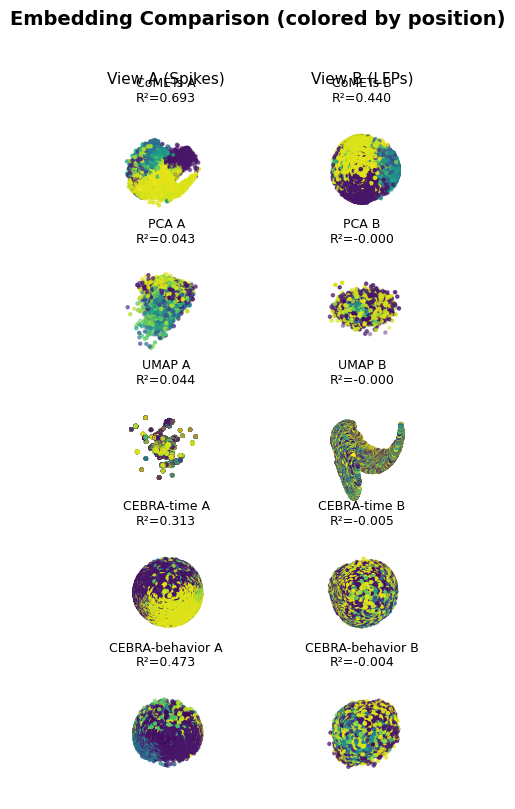

In [16]:

# ============================================================
# VIZ 8: Compact Embedding Comparison (5x2 grid)
# ============================================================
print("\nGenerating compact embedding comparison...")

datasets_top_list = [
    ("CoMETs", ZA_comets),
    ("PCA", ZA_pca),
    ("UMAP", ZA_umap),
    ("CEBRA_time", ZA_cebra_time),
    ("CEBRA_behavior", ZA_cebra_behavior)
]
datasets_bot_list = [
    ("CoMETs", ZB_comets),
    ("PCA", ZB_pca),
    ("UMAP", ZB_umap),
    ("CEBRA_time", ZB_cebra_time),
    ("CEBRA_behavior", ZB_cebra_behavior)
]
titles_left = ["CoMETs", "PCA", "UMAP", "CEBRA-time", "CEBRA-behavior"]
col_titles = ["View A (Spikes)", "View B (LFPs)"]

view_angles_A = [(25,35),(20,45),(25,60),(30,30),(20,70)]
view_angles_B = [(25,35),(20,45),(25,60),(30,30),(20,70)]

fig, axes = plt.subplots(5, 2, figsize=(5, 9),
                         subplot_kw={'projection': '3d'},
                         gridspec_kw={'wspace':0.02, 'hspace':0.1})
color_viz = position_roi
cmap = "viridis"

for r in range(5):
    nameA, ZA_ = datasets_top_list[r]
    axA = axes[r, 0]
    X, Y, Z = reduce_to_3d(ZA_)
    axA.scatter(X, Y, Z, c=color_viz, cmap=cmap, s=5)
    axA.set_title(f"{titles_left[r]} A\nR²={decoding_scores[f'{nameA}_A']:.3f}", fontsize=9, pad=3)
    axA.view_init(*view_angles_A[r])

    nameB, ZB_ = datasets_bot_list[r]
    axB = axes[r, 1]
    X, Y, Z = reduce_to_3d(ZB_)
    axB.scatter(X, Y, Z, c=color_viz, cmap=cmap, s=5)
    axB.set_title(f"{titles_left[r]} B\nR²={decoding_scores[f'{nameB}_B']:.3f}", fontsize=9, pad=3)
    axB.view_init(*view_angles_B[r])

    for ax in (axA, axB):
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
        ax.set_facecolor("white")
        ax.set_box_aspect([1,1,1])
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        ax.grid(False)
        ax.set_axis_off()
        for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
            axis.line.set_color((1,1,1,0))

axes[0,0].text2D(0.5, 1.15, col_titles[0], ha="center", va="bottom", fontsize=11, transform=axes[0,0].transAxes)
axes[0,1].text2D(0.5, 1.15, col_titles[1], ha="center", va="bottom", fontsize=11, transform=axes[0,1].transAxes)

fig.text(0.5, 0.97, "Embedding Comparison (colored by position)", ha="center", fontsize=14, weight="bold")
plt.tight_layout(rect=[0,0,1,0.97])
plt.show()



Generating predicted vs true position plots...


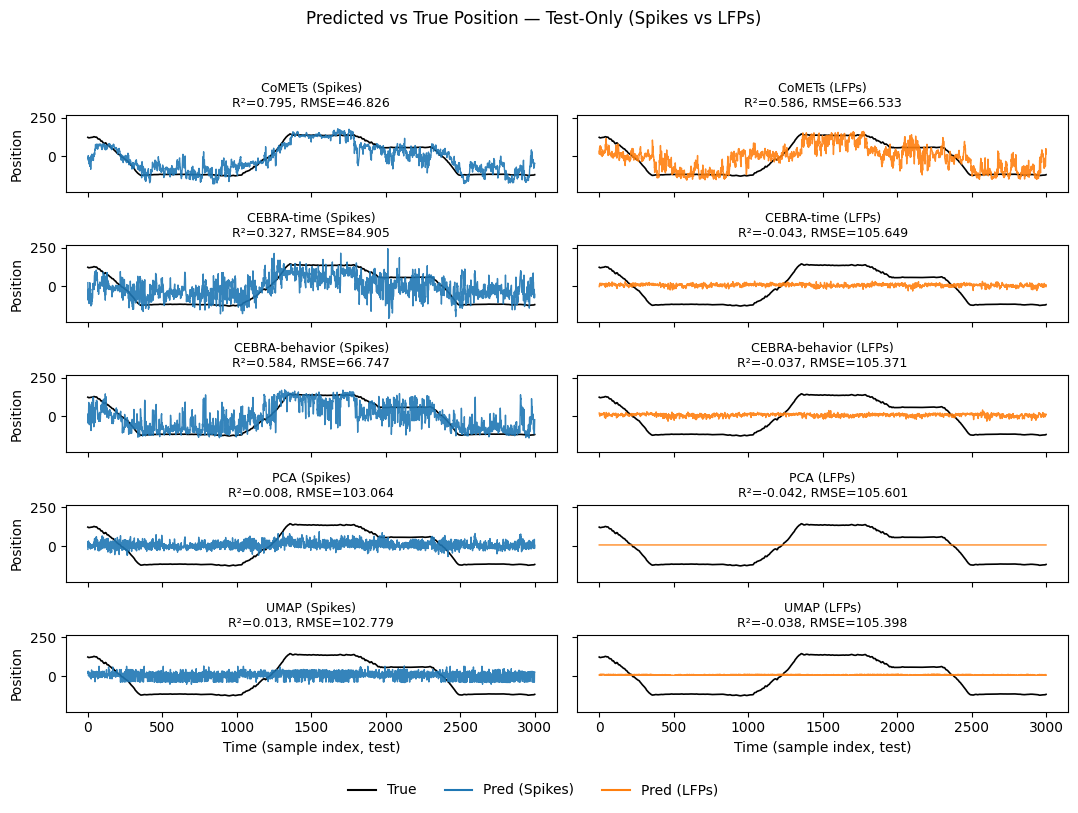

In [17]:

# ============================================================
# VIZ 9: Predicted vs True Position (Test-set only)
# ============================================================
print("\nGenerating predicted vs true position plots...")

Nshow = 3000
models_to_plot = ["CoMETs", "CEBRA_time", "CEBRA_behavior", "PCA", "UMAP"]
position_real = np.asarray(position_roi)

fig, axes = plt.subplots(len(models_to_plot), 2,
                         figsize=(11, 8), sharex=True, sharey=True)
if len(models_to_plot) == 1:
    axes = np.expand_dims(axes, 0)

for i, model in enumerate(models_to_plot):
    for j, view in enumerate(["A", "B"]):
        ax = axes[i, j]
        rec = TRAJECTORY_PREDICTIONS.get((model, view), None)

        if rec is None:
            ax.text(0.5, 0.5, f"No record for {model} ({view})",
                    ha="center", va="center", fontsize=9)
            ax.axis("off")
            continue

        yhat_test = rec["y_pred"]
        ntr = rec["ntr"]
        ytrue_test = position_real[ntr:]
        n = min(Nshow, len(ytrue_test))

        r2 = r2_score(ytrue_test[:n], yhat_test[:n])
        e = compute_rmse(ytrue_test[:n], yhat_test[:n])

        title_name = f"{DISPLAY_NAMES[model]} ({'Spikes' if view=='A' else 'LFPs'})"

        ax.plot(ytrue_test[:n], color="black", lw=1.2, label="True")
        ax.plot(yhat_test[:n],
                color=("tab:blue" if view == "A" else "tab:orange"),
                lw=1.0, alpha=0.9, label="Pred")
        ax.set_title(f"{title_name}\nR²={r2:.3f}, RMSE={e:.3f}", fontsize=9)
        if i == len(models_to_plot) - 1:
            ax.set_xlabel("Time (sample index, test)")
        if j == 0:
            ax.set_ylabel("Position")

legend_elements = [
    plt.Line2D([0], [0], color='black', lw=1.5, label='True'),
    plt.Line2D([0], [0], color='tab:blue', lw=1.5, label='Pred (Spikes)'),
    plt.Line2D([0], [0], color='tab:orange', lw=1.5, label='Pred (LFPs)')
]
fig.legend(handles=legend_elements, loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Predicted vs True Position — Test-Only (Spikes vs LFPs)",
             fontsize=12, y=0.98)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()



Generating bidirectional waveform recovery plots...


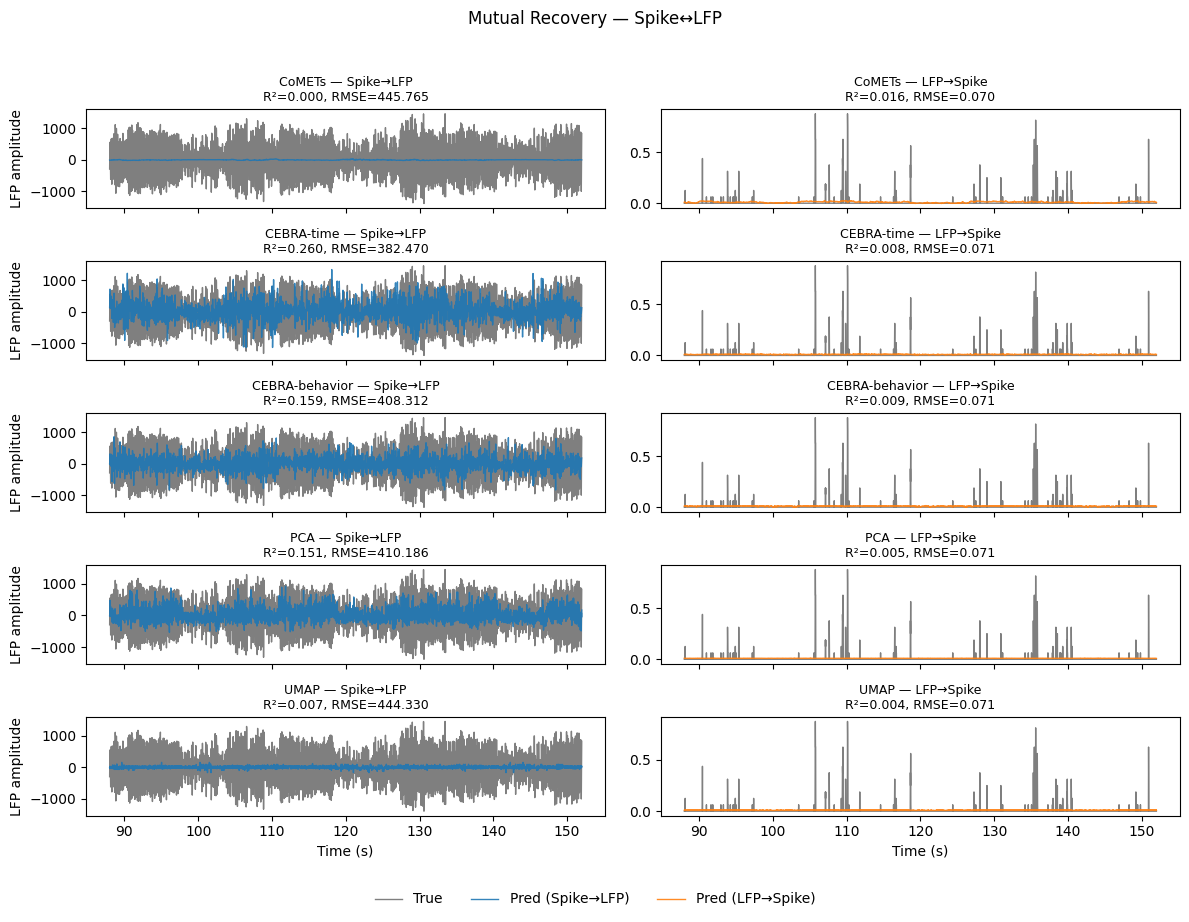

In [18]:

# ============================================================
# VIZ 10: Bidirectional Waveform Recovery
# ============================================================
print("\nGenerating bidirectional waveform recovery plots...")

lfp_targets = np.asarray(lfp_roi)
spike_targets = np.asarray(spike_roi)
T, n_lfp = lfp_targets.shape
_, n_spk = spike_targets.shape

K_BLOCKS, BLOCK_FRAC = 3, 0.08
block_len = int(BLOCK_FRAC * T)
test_mask = np.zeros(T, dtype=bool)
centers = np.linspace(int(0.15*T), int(0.85*T), K_BLOCKS).astype(int)
for c in centers:
    s = max(0, c - block_len//2)
    e = min(T, s + block_len)
    test_mask[s:e] = True
train_mask = ~test_mask

def first_block_span(mask):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return None, None
    splits = np.where(np.diff(idx) > 1)[0]
    starts = np.r_[idx[0], idx[splits+1]]
    ends = np.r_[idx[splits], idx[-1]]
    return int(starts[0]), int(ends[0])

b0, b1 = first_block_span(test_mask)

pred_A2B, pred_B2A = {}, {}
metrics_A2B, metrics_B2A = {}, {}

for name in models_to_plot:
    # Spike → LFP
    X_A = EMBEDDINGS_A[name]
    mA = Ridge(alpha=1.0)
    mA.fit(X_A[train_mask], lfp_targets[train_mask])
    Yhat_A = mA.predict(X_A)
    Y_true_A = lfp_targets
    r2_A = np.mean([r2_score(Y_true_A[test_mask, c], Yhat_A[test_mask, c]) for c in range(n_lfp)])
    err_A = compute_rmse(Y_true_A[test_mask], Yhat_A[test_mask])
    metrics_A2B[name] = (r2_A, err_A)
    pred_A2B[name] = mA.predict(X_A[b0:b1+1])

    # LFP → Spike
    X_B = EMBEDDINGS_B[name]
    mB = Ridge(alpha=1.0)
    mB.fit(X_B[train_mask], spike_targets[train_mask])
    Yhat_B = mB.predict(X_B)
    Y_true_B = spike_targets
    r2_B = np.mean([r2_score(Y_true_B[test_mask, c], Yhat_B[test_mask, c]) for c in range(n_spk)])
    err_B = compute_rmse(Y_true_B[test_mask], Yhat_B[test_mask])
    metrics_B2A[name] = (r2_B, err_B)
    pred_B2A[name] = mB.predict(X_B[b0:b1+1])

t_block = np.arange(b0, b1+1) / fs_common
lfp_ch, spk_ch = 0, 0

fig, axes = plt.subplots(len(models_to_plot), 2,
                         figsize=(12, 9), sharex=True)

for i, name in enumerate(models_to_plot):
    axL = axes[i, 0]
    axL.plot(t_block, lfp_targets[b0:b1+1, lfp_ch], color="black", lw=1.0, alpha=0.5)
    axL.plot(t_block, pred_A2B[name][:, lfp_ch], color="tab:blue", lw=1.0, alpha=0.9)
    r2_A, err_A = metrics_A2B[name]
    axL.set_title(f"{DISPLAY_NAMES[name]} — Spike→LFP\nR²={r2_A:.3f}, RMSE={err_A:.3f}", fontsize=9)
    if i == len(models_to_plot)-1:
        axL.set_xlabel("Time (s)")
    axL.set_ylabel("LFP amplitude")

    axR = axes[i, 1]
    axR.plot(t_block, spike_targets[b0:b1+1, spk_ch], color="black", lw=1.0, alpha=0.5)
    axR.plot(t_block, pred_B2A[name][:, spk_ch], color="tab:orange", lw=1.0, alpha=0.9)
    r2_B, err_B = metrics_B2A[name]
    axR.set_title(f"{DISPLAY_NAMES[name]} — LFP→Spike\nR²={r2_B:.3f}, RMSE={err_B:.3f}", fontsize=9)
    if i == len(models_to_plot)-1:
        axR.set_xlabel("Time (s)")

legend_elements = [
    plt.Line2D([0], [0], color='black', lw=1, label='True', alpha=0.5),
    plt.Line2D([0], [0], color='tab:blue', lw=1, label='Pred (Spike→LFP)', alpha=0.9),
    plt.Line2D([0], [0], color='tab:orange', lw=1, label='Pred (LFP→Spike)', alpha=0.9)
]
fig.legend(handles=legend_elements, loc="lower center", ncol=3,
           frameon=False, bbox_to_anchor=(0.5, -0.02))

fig.suptitle("Mutual Recovery — Spike↔LFP", fontsize=12, y=0.99)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()



Generating final figure with emphasized embeddings...


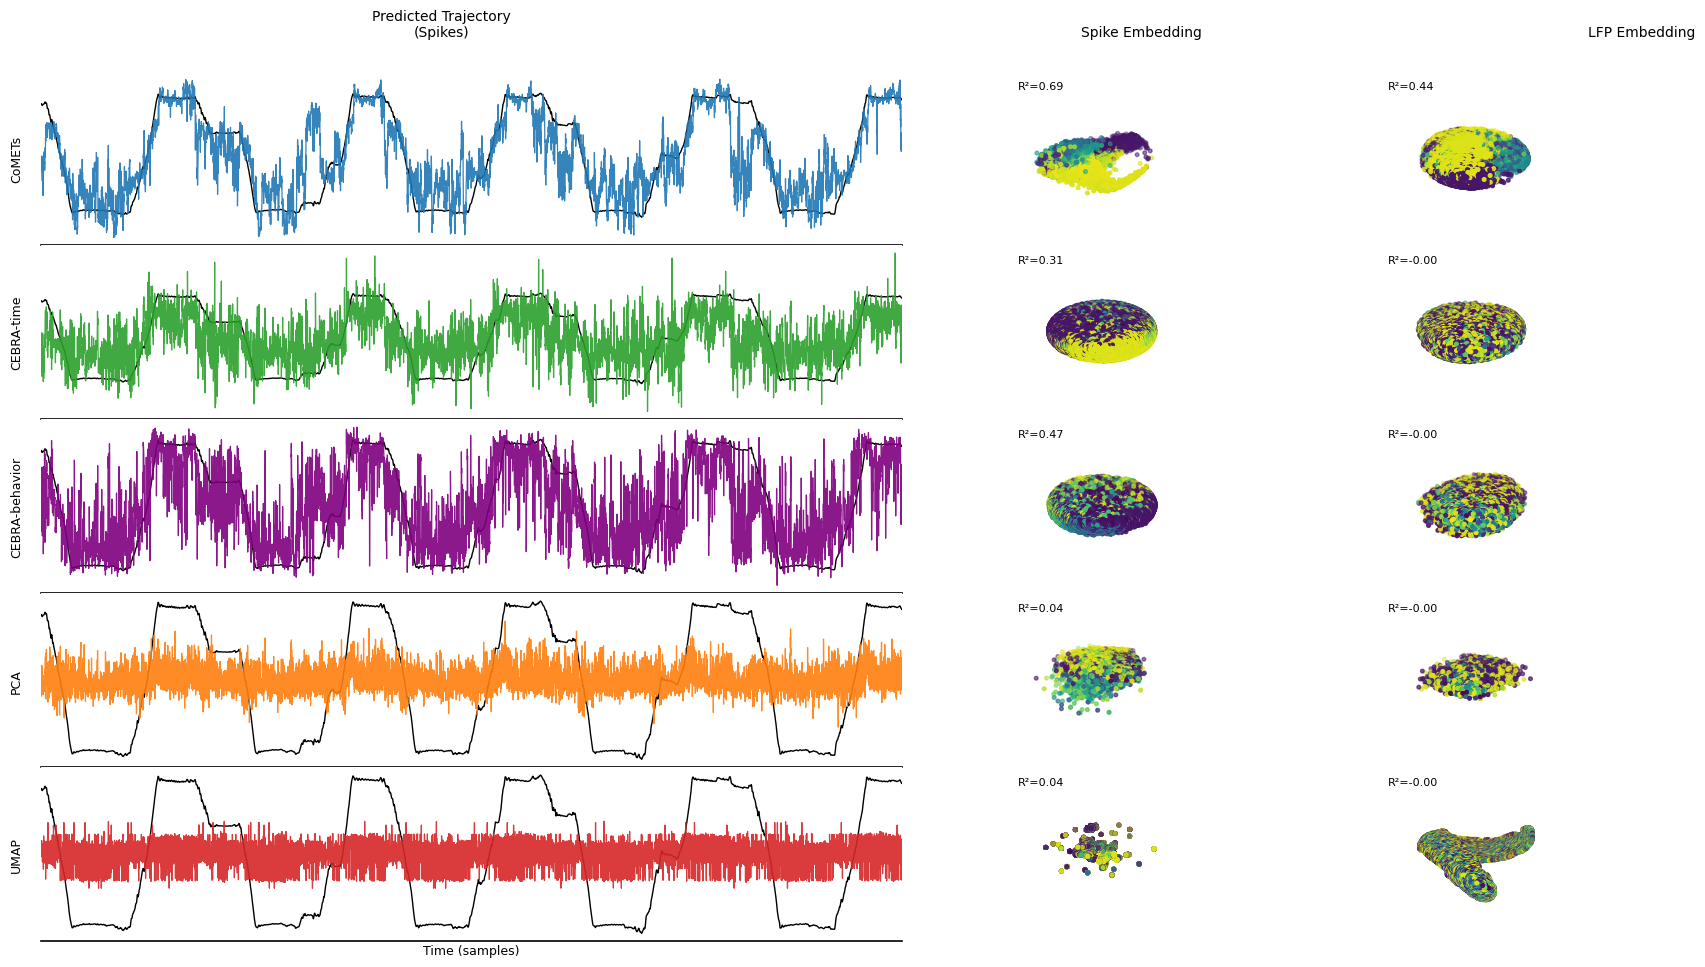


✓ All visualizations complete!


In [19]:
# ============================================================
# VIZ 11: Final Figure — Emphasized Embeddings (Consistent X-Axis)
# ============================================================
print("\nGenerating final figure with emphasized embeddings...")
model_colors = dict(CoMETs="tab:blue", CEBRA_time="tab:green", CEBRA_behavior = 'purple',
                    PCA="tab:orange", UMAP="tab:red")

n_models = len(models_to_plot)
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(
    n_models, 3,
    width_ratios=[5, 2, 2],
    wspace=0.05, hspace=0.0
)

for i, model in enumerate(models_to_plot):
    # length of the visible segment (e.g., 2000 samples)
    T_window = 10000  

    # --------------------------------------------------------
    # (1) Trajectory (left) — only bottom axis line visible
    # --------------------------------------------------------
    ax1 = fig.add_subplot(gs[i, 0])
    rec = TRAJECTORY_PREDICTIONS.get((model, "A"), None)

    if rec is not None:
        yhat_test = rec["y_pred"]
        ntr = rec["ntr"]
        ytrue_test = position_real[ntr:]
        n = min(len(ytrue_test), len(yhat_test))

        # determine slice for partial view
        n_show = min(T_window, n)
        idx_show = slice(0, n_show)

        # --- plot true (black) and predicted (model color) ---
        ax1.plot(ytrue_test[idx_show], color="black", lw=1.0, label="True")
        ax1.plot(
            yhat_test[idx_show],
            color=model_colors.get(model.replace("-", "_"), "tab:gray"),
            lw=0.9, alpha=0.9, label="Pred"
        )

    # --- Clean up spines and ticks ---
    for spine in ["top", "left", "right"]:
        ax1.spines[spine].set_visible(False)
    ax1.spines["bottom"].set_visible(True)
    ax1.spines["bottom"].set_linewidth(1.2)
    ax1.spines["bottom"].set_color("black")

    # remove ticks but keep the line
    ax1.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    # only last row gets visible x-axis label
    if i == n_models - 1:
        ax1.set_xlabel("Time (samples)", fontsize=9, labelpad=2)
        ax1.spines["bottom"].set_linewidth(1.2)
        ax1.spines["bottom"].set_color("black")

    # consistent limits
    ax1.set_xlim(0, n_show)
    ax1.set_ylabel(DISPLAY_NAMES[model], rotation=90, fontsize=9,
                labelpad=18, va="center")
    # --------------------------------------------------------
    # (2) Spike embedding (center)
    # --------------------------------------------------------
    ax2 = fig.add_subplot(gs[i, 1], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_A[model])
    ax2.scatter(X, Y, Z, c=color_viz, cmap=cmap, s=7)
    ax2.view_init(25, 35)
    ax2.text2D(0.03, 0.90, f"R²={decoding_scores[f'{model}_A']:.2f}",
               transform=ax2.transAxes, fontsize=8)
    ax2.set_axis_off()
    ax2.set_box_aspect([5, 5, 2])

    # --------------------------------------------------------
    # (3) LFP embedding (right)
    # --------------------------------------------------------
    ax3 = fig.add_subplot(gs[i, 2], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_B[model])
    ax3.scatter(X, Y, Z, c=color_viz, cmap=cmap, s=7)
    ax3.view_init(25, 35)
    ax3.text2D(0.03, 0.90, f"R²={decoding_scores[f'{model}_B']:.2f}",
               transform=ax3.transAxes, fontsize=8)
    ax3.set_axis_off()
    ax3.set_box_aspect([5, 5, 2])

# ------------------------------------------------------------
# Layout and headers
# ------------------------------------------------------------
plt.subplots_adjust(
    wspace=0.01, hspace=0.03,
    left=0.05, right=0.85,
    top=0.92, bottom=0.05
)

fig.text(0.25, 0.955, "Predicted Trajectory\n(Spikes)", ha="center",
         fontsize=10)
fig.text(0.6, 0.955, "Spike Embedding", ha="center",
         fontsize=10)
fig.text(0.85, 0.955, "LFP Embedding", ha="center",
         fontsize=10)

plt.show()

print("\n✓ All visualizations complete!")



Generating final figure with embeddings...


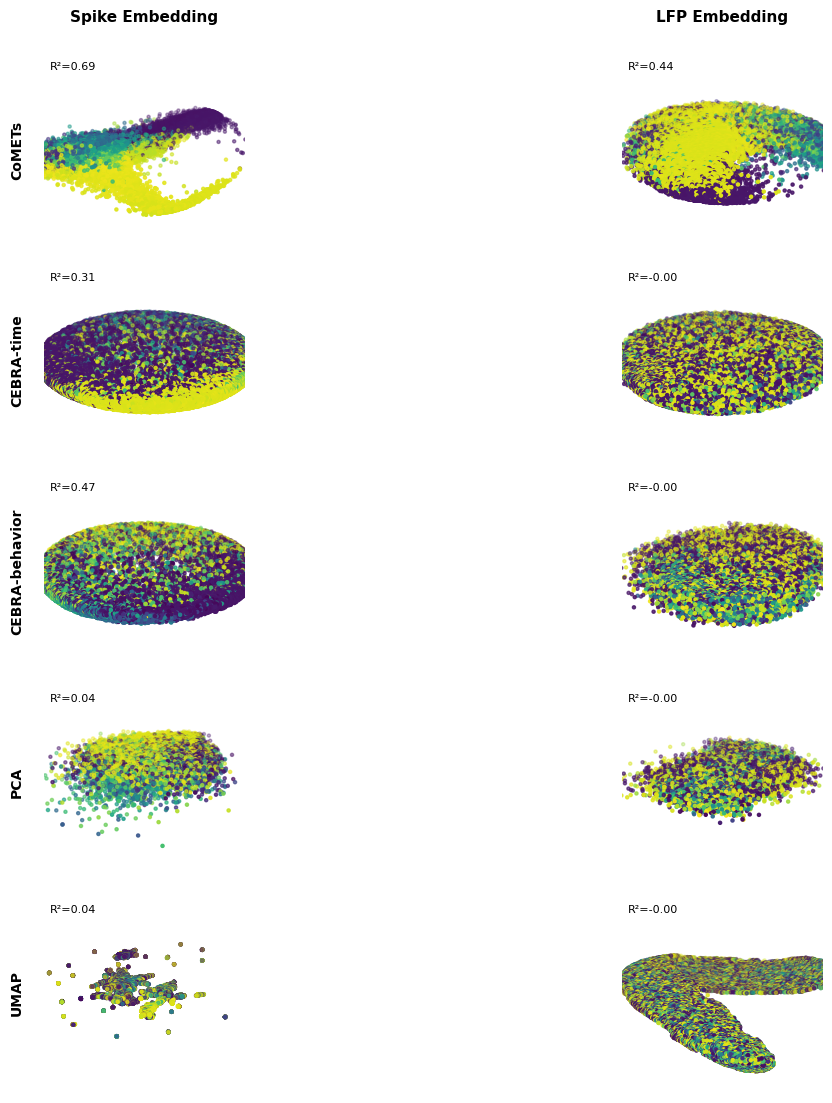


✓ Visualization complete!


In [20]:
# ============================================================
# Final Figure — Embeddings Only (5x2)
# ============================================================
print("\nGenerating final figure with embeddings...")

models_to_plot = ["CoMETs", "CEBRA_time", "CEBRA_behavior", "PCA", "UMAP"]
n_models = len(models_to_plot)
color_viz = position_roi
cmap = "viridis"

# Zoom ratio for 3D plots (adjust this value to zoom in/out)
zoom_ratio = 1.5  # >1 zooms in, <1 zooms out

fig = plt.figure(figsize=(12, 12))
gs = fig.add_gridspec(
    n_models, 2,
    wspace=0.15, hspace=0.05,
    left=0.05, right=0.95, top=0.92, bottom=0.05
)

for i, model in enumerate(models_to_plot):
    # Spike embedding (left)
    ax1 = fig.add_subplot(gs[i, 0], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_A[model])
    ax1.scatter(X, Y, Z, c=color_viz, cmap=cmap, s=5)
    ax1.view_init(25, 35)
    
    # Zoom in/out by adjusting axis limits
    x_range = X.max() - X.min()
    y_range = Y.max() - Y.min()
    z_range = Z.max() - Z.min()
    x_center = (X.max() + X.min()) / 2
    y_center = (Y.max() + Y.min()) / 2
    z_center = (Z.max() + Z.min()) / 2
    
    ax1.set_xlim(x_center - x_range/(2*zoom_ratio), x_center + x_range/(2*zoom_ratio))
    ax1.set_ylim(y_center - y_range/(2*zoom_ratio), y_center + y_range/(2*zoom_ratio))
    ax1.set_zlim(z_center - z_range/(2*zoom_ratio), z_center + z_range/(2*zoom_ratio))
    
    ax1.text2D(0.03, 0.90, f"R²={decoding_scores[f'{model}_A']:.2f}",
               transform=ax1.transAxes, fontsize=8)
    ax1.set_axis_off()
    ax1.set_box_aspect([5, 5, 1])
    
    # Add method label on the left
    if i == 0:
        ax1.set_title("Spike Embedding", fontsize=11, weight="bold", pad=20)
    ax1.text2D(-0.1, 0.5, DISPLAY_NAMES[model], transform=ax1.transAxes,
               fontsize=10, weight="bold", rotation=90, va="center", ha="right")
    
    # LFP embedding (right)
    ax2 = fig.add_subplot(gs[i, 1], projection="3d")
    X, Y, Z = reduce_to_3d(EMBEDDINGS_B[model])
    ax2.scatter(X, Y, Z, c=color_viz, cmap=cmap, s=5)
    ax2.view_init(25, 35)
    
    # Zoom in/out by adjusting axis limits
    x_range = X.max() - X.min()
    y_range = Y.max() - Y.min()
    z_range = Z.max() - Z.min()
    x_center = (X.max() + X.min()) / 2
    y_center = (Y.max() + Y.min()) / 2
    z_center = (Z.max() + Z.min()) / 2
    
    ax2.set_xlim(x_center - x_range/(2*zoom_ratio), x_center + x_range/(2*zoom_ratio))
    ax2.set_ylim(y_center - y_range/(2*zoom_ratio), y_center + y_range/(2*zoom_ratio))
    ax2.set_zlim(z_center - z_range/(2*zoom_ratio), z_center + z_range/(2*zoom_ratio))
    
    ax2.text2D(0.03, 0.90, f"R²={decoding_scores[f'{model}_B']:.2f}",
               transform=ax2.transAxes, fontsize=8)
    ax2.set_axis_off()
    ax2.set_box_aspect([5, 5, 1])
    
    if i == 0:
        ax2.set_title("LFP Embedding", fontsize=11, weight="bold", pad=20)

# fig.suptitle("Spikes (A) vs LFP (B): Embedding Comparison",
#              fontsize=13, weight="bold", y=0.98)

plt.show()

print("\n✓ Visualization complete!")


Generating trajectory-only figure...


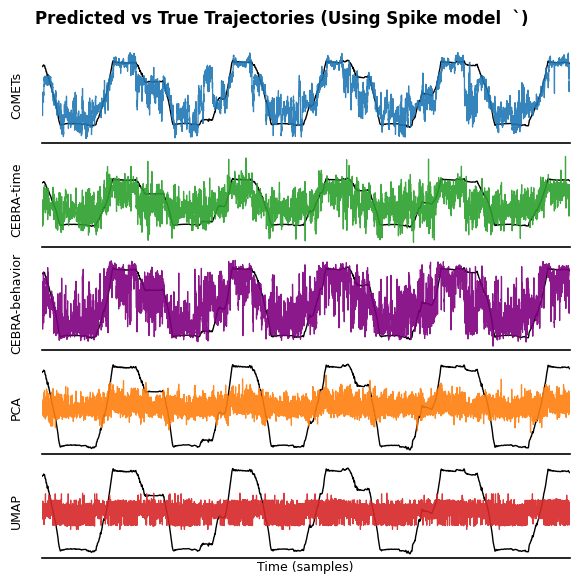


✓ Trajectory-only visualization complete!


: 

In [ ]:
# ============================================================
# VIZ 11: Predicted Trajectories Only (Clean Version)
# ============================================================
print("\nGenerating trajectory-only figure...")

# ------------------------------------------------------------
# Setup
# ------------------------------------------------------------
model_colors = dict(
    CoMETs="tab:blue",
    CEBRA_time="tab:green",
    CEBRA_behavior="purple",
    PCA="tab:orange",
    UMAP="tab:red"
)

T_window = 10000   # number of samples to visualize
n_models = len(models_to_plot)

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(6, 6),
    sharex=False,
    constrained_layout=False
)

if n_models == 1:
    axes = [axes]

for i, (ax, model) in enumerate(zip(axes, models_to_plot)):
    rec = TRAJECTORY_PREDICTIONS.get((model, "A"), None)

    if rec is not None:
        yhat_test = rec["y_pred"]
        ntr = rec["ntr"]
        ytrue_test = position_real[ntr:]
        n = min(len(ytrue_test), len(yhat_test))
        n_show = min(T_window, n)
        idx_show = slice(0, n_show)

        # --- Plot true and predicted trajectories ---
        ax.plot(ytrue_test[idx_show], color="black", lw=1.0, label="True")
        ax.plot(
            yhat_test[idx_show],
            color=model_colors.get(model.replace("-", "_"), "tab:gray"),
            lw=0.9, alpha=0.9, label="Pred"
        )

    # --- Styling: minimalist axis, only bottom spine visible ---
    for spine in ["top", "left", "right"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.spines["bottom"].set_color("black")

    # remove all ticks but keep bottom line
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    # label only bottom subplot
    if i == n_models - 1:
        ax.set_xlabel("Time (samples)", fontsize=9, labelpad=2)
    else:
        ax.spines["bottom"].set_visible(True)

    # Y-label = model name
    ax.set_ylabel(DISPLAY_NAMES[model], rotation=90, fontsize=9,
                  labelpad=18, va="center")
    ax.set_xlim(0, n_show)

# ------------------------------------------------------------
# Layout and caption
# ------------------------------------------------------------
plt.subplots_adjust(
    hspace=0.1,
    left=0.1, right=0.98,
    top=0.93, bottom=0.08
)

fig.text(0.5, 0.97, "Predicted vs True Trajectories (Using Spike model  `)",
         ha="center", fontsize=12, weight="bold")

plt.show()

print("\n✓ Trajectory-only visualization complete!")
